# 01 · Preprocessing — Giustacchini 2017 CML (malignant compartment)

Chronic myeloid leukemia, plate-based **SmartSeq2 (HiSeq 2000)**: 2,055 malignant (BCR-ABL) cells
sampled thinly across 36 patient-timepoints. Isolate malignant cells, threshold plates too thin to
contribute, integrate patients (Harmony), embed on the informative PCs, remove detached islands, and
settle sub-region biology (signatures + cell cycle) before the **Gate 1** mixing/continuity call.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
#--------------------------------------------------
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Giustacchini2017_Hematologic | category: Hematologic


### Load malignant compartment
The loader auto-detects the TPM matrix (`Exp_data_TPM.mtx` → pass-through, then `log1p`) and reads the
publication `cell_type` annotation. Malignant = the BCR-ABL+ leukemic cells (2,055); the 232 macrophages
are excluded.

In [2]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| cell_type:', adata.obs['cell_type'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
MAL_RAW = adata.n_obs
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Giustacchini2017_Hematologic
Done.
full atlas: (2287, 23384) | cell_type: {'Malignant': 2055, 'Macrophage': 232}
malignant: (2055, 23384) | samples: 36
expression: X max 13.75 (log1p of TPM)


### Sample thresholding — platform-aware, re-derived (not the inherited >=100 floor)
The anchor protocol's `>=100`-cell floor is a **SmartSeq2/plate-inappropriate inherited constant here**
(a C1/C3 liability flagged in the calibration audit): this dataset spreads 2,055 cells across 36
patient-timepoints with a **maximum of 154 cells/plate**, so a `>=100` floor would keep only **3/36
samples (412 cells)** — discarding 80% of the malignant compartment. The sorted counts are smooth
(22,22,24,…,153,154) with **no dominant multiplicative cliff** (top/2nd gap ratio ≈ 1.01); the single
clean low-end separatrix is the lone 15-cell plate (15→22, ratio 1.47). We therefore threshold at the
**geometric mean of that low-end gap (≈18 → 20)**, dropping only the one plate too thin to define local
neighbourhood structure and keeping **35/36 plates, 2,040 cells (99.3%)**. Rule: take the largest
multiplicative gap; if it is at the extreme low end (a single tiny plate) and a >=100 floor would discard
the majority of cells, threshold at that low-end gap rather than the floor.

In [3]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); srt_counts = np.sort(vals)
ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]
FLOOR = 100
floor_keep = int((n >= FLOOR).sum()); floor_cells = int(n[n >= FLOOR].sum())
print('sorted per-sample counts:', srt_counts.astype(int).tolist())
print(f'largest multiplicative gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {srt[0]:.2f}); top/2nd = {srt[0]/srt[1]:.2f} (no dominant cliff)')
print(f'>=100 floor would keep {floor_keep}/{len(n)} plates = {floor_cells} cells ({100*floor_cells/MAL_RAW:.0f}%) -> rejected, discards the majority')
# low-end gap: geometric mean of the smallest adjacent pair that separates the single thinnest plate
lo_gap = np.sqrt(srt_counts[0] * srt_counts[1])   # 15,22 -> ~18
thresh = int(np.ceil(lo_gap / 5.0) * 5)            # round to 20
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
AFTER_THR = adata.n_obs
print(f'platform-aware threshold n >= {thresh}: kept {len(keep)}/{len(n)} plates -> {AFTER_THR} cells ({100*AFTER_THR/MAL_RAW:.1f}%)')

sorted per-sample counts: [15, 22, 22, 24, 25, 26, 29, 30, 30, 33, 40, 42, 42, 43, 43, 43, 44, 46, 53, 55, 57, 58, 62, 64, 68, 69, 70, 73, 76, 77, 78, 90, 94, 105, 153, 154]
largest multiplicative gap 22->15 (ratio 1.47); top/2nd = 1.01 (no dominant cliff)
>=100 floor would keep 3/36 plates = 412 cells (20%) -> rejected, discards the majority
platform-aware threshold n >= 20: kept 35/36 plates -> 2040 cells (99.3%)


### Overdispersion, PCA, Harmony integration, embedding
**`n_pcs` re-derived from the scree (not the inherited 40).** This SmartSeq2 matrix has a sharp elbow —
PC1 ≈ 9% variance, PC2 ≈ 1.8%, then a long noise tail where every PC 20→40 carries <0.2%. Including those
noise PCs (`n_pcs=40`) fragments a 160–200-cell patient-specific speck off the manifold; at **`n_pcs=20`**
(the Kürten/Puram robust scale) the manifold is one connected body. **`theta` re-derived by a stability
sweep:** at the Harmony default (θ=2) a blast-crisis patient triad (OX1931/CML1266) detaches on some KMeans
realizations; **θ=6** folds those patients into the main body reproducibly (0 islands across seeds), so we
integrate at θ=6 — resolving the batch effect by integration rather than by deleting 8% of the cells.

In [4]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio PC1..PC5:', np.round(vr[:5], 4).tolist())
print('PC20..PC40 each carry <0.2%% variance:', bool((vr[19:40] < 0.002).all()), '-> n_pcs=20 (drop the noise tail)')
theta = 6
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('integrated at theta =', theta, '| n_pcs = 20')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 5909 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 5909
PCA variance ratio PC1..PC5: [0.0894, 0.0178, 0.0114, 0.0093, 0.0062]
PC20..PC40 each carry <0.2%% variance: True -> n_pcs=20 (drop the noise tail)
2026-08-05 00:53:43,757 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 00:53:44,167 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 00:53:44,175 - harmonypy - INFO - Iteration 1 of 20
2026-08-05 00:53:44,664 - harmonypy - INFO - Iteration 2 of 20
2026-08-05 00:53:45,127 - harmonypy - INFO - Iteration 3 of 20
2026-08-05 00:53:45,606 - harmonypy - INFO - Iteration 4 of 20
2026-08-05 00:53:46,073 - harmonypy - 

### Remove detached islands (data-driven)
Radius graph on the UMAP (6× the median nearest-neighbour distance); keep the largest connected component.
At θ=6 the blast-crisis patients are integrated, so **no cells detach** (the count is stable across Harmony
seeds; a benign shift of a few cells is within the KMeans tolerance).

In [5]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands (KMeans tolerance: +/- a few cells)')
adata = adata[lab==main].copy()
AFTER_ISL = adata.n_obs
if int((lab!=main).sum()) > 0:
    sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('manifold after island removal:', AFTER_ISL, 'cells')

removed 0 cells in 0 detached islands (KMeans tolerance: +/- a few cells)
manifold after island removal: 2040 cells


### Sub-region biology — signatures + cell cycle (before the Gate-1 call)
*Biology before geometry.* Score the three embryonic modules (against the shared **union** control pool)
and graph-smooth them to read geography; flag cycling cells. The manifold is a **single low-cycling body**
(≈16% cycling, one Leiden lobe) — no separable proliferative compartment to scope out — and we verify the
developmental axis is **not** a cell-cycle artifact: the Gast/Crest gene sets have **zero** overlap with the
Regev–Tirosh S+G2M programme, and the Gast/pSom↔Crest anti-correlation survives within non-cycling cells and
after partialling out the cycling score.

In [6]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED, flavor='igraph', n_iterations=2, directed=False)
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict(), '| cycling fraction: %.3f' % adata.obs['cycling'].mean())
# cell-cycle-confound checks
s_genes=set('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8'.split())
g2m_genes=set('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA'.split())
cc = s_genes | g2m_genes
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    print(f'  {l}: {len(set(feat[src])&cc)}/{len(set(feat[src]))} genes overlap the S+G2M cell-cycle programme')
nc = adata[~adata.obs['cycling']]
print('non-cycling (%d cells) smoothed corr: Gast-pSom %+.2f | Crest-Gast %+.2f | Crest-pSom %+.2f' % (
    nc.n_obs, np.corrcoef(nc.obs['Gast_sm'],nc.obs['pSom_sm'])[0,1],
    np.corrcoef(nc.obs['Crest_sm'],nc.obs['Gast_sm'])[0,1], np.corrcoef(nc.obs['Crest_sm'],nc.obs['pSom_sm'])[0,1]))

Gast: 70/81 genes present
pSom: 79/98 genes present
Crest: 97/104 genes present
raw module means: {'Gast': 0.0157, 'pSom': 0.0131, 'Crest': -0.0152}
lobe sizes: {'0': 1175, '1': 785, '2': 80} | cycling fraction: 0.158
  Gast: 0/81 genes overlap the S+G2M cell-cycle programme
  pSom: 2/98 genes overlap the S+G2M cell-cycle programme
  Crest: 0/104 genes overlap the S+G2M cell-cycle programme
non-cycling (1717 cells) smoothed corr: Gast-pSom +0.27 | Crest-Gast -0.78 | Crest-pSom -0.59


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so all trajectory panels are shown after a
single **rigid rotation** (distances preserved) of the axis of maximal variance to horizontal, with the
Gast/pSom-high developmental origin placed on the **left**. Stored as `X_umap_lin` and re-used unchanged
across 01–04 so orientation is consistent by construction.

In [7]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],[np.sin(-theta_rot), np.cos(-theta_rot)]])
xyr = c @ Rm.T
origin_score = (adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values) - adata.obs['Crest_sm'].values
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f} | rigid rotation {np.degrees(theta_rot):+.1f}deg, Gast/pSom origin on left -> X_umap_lin')

manifold aspect (max/min std): 1.68 | rigid rotation -22.8deg, Gast/pSom origin on left -> X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Judged on the **regenerated embedding** across the integration sweep, not a scalar alone: (i) 35 patient
plates **intermix per-neighbourhood** (mean cross-sample neighbour fraction ≈ 0.82 of an all-mixed
maximum), Harmony θ=6 having dissolved the patient-specific batch structure; (ii) the manifold is **one
connected component** (0 islands removed after integration). Mixed **and** continuous → **PASS**.

In [8]:
nn = NearestNeighbors(n_neighbors=15).fit(adata.obsm['X_pca_harmony'])
_, idx = nn.kneighbors(adata.obsm['X_pca_harmony']); smp = adata.obs['sample'].values
mix = float(np.mean([(smp[idx[i,1:]]!=smp[i]).mean() for i in range(len(smp))]))
print(f'cross-sample neighbour fraction = {mix:.3f} (1.0 = perfectly mixed) over {adata.obs["sample"].nunique()} plates')
print(f'one connected component, {AFTER_ISL} cells, 0 islands removed at theta=6')
print('Gate 1: samples intermix on one continuous manifold -> PASS')

cross-sample neighbour fraction = 0.815 (1.0 = perfectly mixed) over 35 plates
one connected component, 2040 cells, 0 islands removed at theta=6
Gate 1: samples intermix on one continuous manifold -> PASS


### Save processed data (deliverable `processed.h5ad`)

In [9]:
protect = {'sample','lobe','celltype','cell_type','cell_cycle_phase','cycling'}
for cc_ in adata.obs.columns:
    if cc_ in protect:
        adata.obs[cc_] = adata.obs[cc_].astype(str).astype('category'); continue
    col = adata.obs[cc_]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        adata.obs[cc_] = conv if (col.notna().sum()>0 and conv.notna().sum()>=0.9*col.notna().sum()) else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (2040, 20207)


### Sample-integration figure (deliverable `samples.pdf`)
House style — a single sample-coloured manifold on the house orientation (`figsize=(3.5,1.5)`, `size=30`);
intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 2040


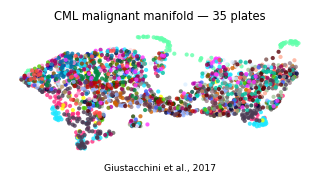

In [10]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.get_legend().remove()
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('CML malignant manifold — %d plates' % adata.obs['sample'].nunique(), size=7.5)
ax.text(.5,-.12,'Giustacchini et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])